<h1>Lab01 — sprint 2</h1>
<h2>Сходимость оценок генератора</h2>
<h3>Description</h3>

Фиксируем крепость 12% об. и k = 720. Распределение строим только по train.
Для каждого объёма от 10 до 100 000 получаем 500 выборок. В каждом повторе используем вложенные выборки: увеличиваем одну последовательность.
Сравниваем среднее и исправленную дисперсию с точными характеристиками фиксированной модели. Test здесь не нужен.

In [2]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, inverse_cdf
meta=json.loads((ROOT/'data/processed/alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]

values,p=quality_distribution(train.alcohol,train.quality,12.,k=720)
mu=values@p
variance=((values-mu)**2)@p
moment4=((values-mu)**4)@p
print(f'Среднее модели: {mu:.6f}; дисперсия: {variance:.6f}')


Среднее модели: 6.375315; дисперсия: 0.670222


<h3>math desc</h3>

При фиксированной модели сгенерированные оценки рассматриваем как независимые и одинаково распределённые. Они ограничены, поэтому все моменты конечны. По закону больших чисел среднее и средний квадрат сходятся к своим ожиданиям. Отсюда сходится и исправленная дисперсия:

$$
\bar Q_n\xrightarrow{P}\mu,\qquad S_n^2=\frac{n}{n-1}\left(\overline{Q^2}_n-\bar Q_n^2\right)\xrightarrow{P}\sigma^2.
$$

Обе оценки несмещённые. Их теоретические среднеквадратические ошибки равны:

$$
\operatorname{RMSE}(\bar Q_n)=\frac{\sigma}{\sqrt n},\qquad
\operatorname{RMSE}(S_n^2)=\sqrt{\frac{1}{n}\left(\mu_4-\frac{n-3}{n-1}\sigma^4\right)},
\quad \mu_4=E[(Q-\mu)^4].
$$

Проверим эти зависимости по повторным генерациям. Ошибка отдельной последовательности может временно расти: сходимость не означает монотонного приближения. Здесь проверяем точность генерации заданного распределения; увеличение n не исправляет расхождение модели с реальными винами.

In [4]:
sizes=np.array([10,30,100,300,1000,3000,10000,30000,100000])
repeats=500
rng=np.random.default_rng(2027)
means=np.empty((repeats,len(sizes)))
variances=np.empty_like(means)
for r in range(repeats):
    sample=inverse_cdf(values,p,rng.random(sizes[-1])).astype(float)
    sums=np.cumsum(sample)[sizes-1]
    squares=np.cumsum(sample**2)[sizes-1]
    means[r]=sums/sizes
    variances[r]=(squares-sums**2/sizes)/(sizes-1)
result=pd.DataFrame({'n':sizes,
    'mean_bias':(means-mu).mean(axis=0),
    'mean_rmse':np.sqrt(((means-mu)**2).mean(axis=0)),
    'mean_rmse_theory':np.sqrt(variance/sizes),
    'variance_bias':(variances-variance).mean(axis=0),
    'variance_rmse':np.sqrt(((variances-variance)**2).mean(axis=0)),
    'variance_rmse_theory':np.sqrt((moment4-(sizes-3)/(sizes-1)*variance**2)/sizes)})
display(result.round(6))
result.to_csv(ROOT/'reports/tables/generator_convergence.csv',index=False)


,n,mean_bias,mean_rmse,mean_rmse_theory,variance_bias,variance_rmse,variance_rmse_theory
0,10,0.003685,0.265768,0.258886,0.014156,0.407098,0.375721
1,30,0.011218,0.152308,0.149468,0.005282,0.217039,0.211567
2,100,0.002825,0.083704,0.081867,0.004234,0.121348,0.114931
3,300,0.000818,0.047256,0.047266,-0.000993,0.066813,0.066203
4,1000,-0.001247,0.025967,0.025889,-0.000572,0.035098,0.036232
5,3000,-0.000964,0.015582,0.014947,0.000167,0.020598,0.020914
6,10000,-0.000767,0.008417,0.008187,0.000682,0.010864,0.011454
7,30000,-0.000159,0.004653,0.004727,0.000282,0.006317,0.006613
8,100000,0.000031,0.002574,0.002589,0.000246,0.003719,0.003622


<h3>tests — ошибки оценок</h3>

RMSE вычисляем по 500 повторениям. Обе оси логарифмические: так виден масштаб уменьшения ошибки.

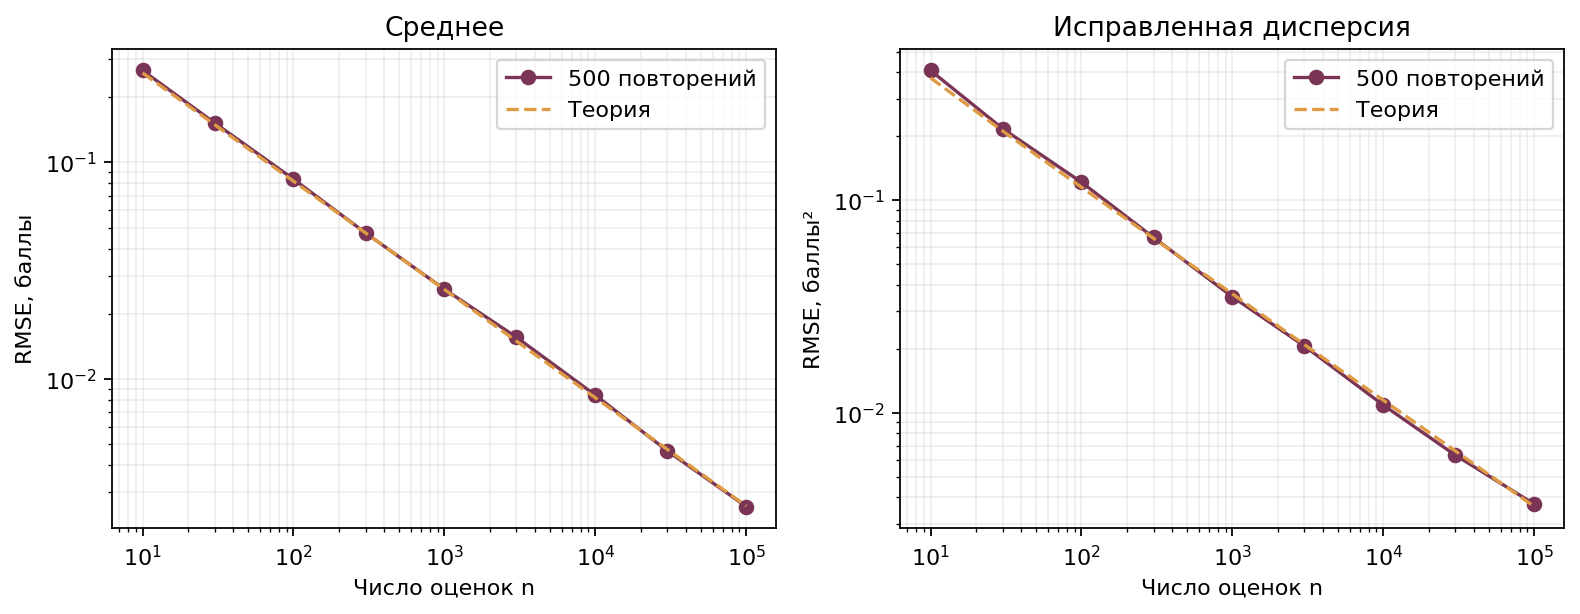

In [6]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,metric,title,unit in zip(axes,['mean','variance'],['Среднее','Исправленная дисперсия'],['баллы','баллы²']):
    ax.loglog(sizes,result[metric+'_rmse'],'o-',label='500 повторений',color='#7a3455')
    ax.loglog(sizes,result[metric+'_rmse_theory'],'--',label='Теория',color='#df9b44')
    ax.set(xlabel='Число оценок n',ylabel='RMSE, '+unit,title=title)
    ax.grid(alpha=.2,which='both')
    ax.legend()
fig.tight_layout()
path=ROOT/'reports/figures/generator_convergence.png'
fig.savefig(path,dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(path)))


<h3>resume</h3>

При увеличении объёма с 10 до 100 000 RMSE среднего уменьшилась с 0.2658 до 0.0026 балла, а RMSE исправленной дисперсии — с 0.4071 до 0.0037 балла².
При n = 100 000 теория даёт соответственно 0.0026 и 0.0036.

Результаты согласуются с теоретическим уменьшением ошибки порядка 1/√n и иллюстрируют состоятельность оценок для фиксированного распределения генератора. Конечный эксперимент сам по себе не доказывает предел. Расхождение с реальными данными, найденное ранее, относится к модели и от числа генераций не исчезает.